In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import numpy as np
import jax
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from pathlib import Path
from jax import random, vmap
from jax.lax import scan, dot_general, dynamic_slice_in_dim
from jax.nn import gelu
from jax.tree_util import tree_map, tree_leaves

%config InlineBackend.figure_format='retina'

# A toy foundation model

A *foundation model* is a large model pretrained on a broad and diverse set of data, which is then adapted (*finetuned*) to a specific task with a small amount of task-specific data. The idea is that what the model learns during the pretraining (here: elementary pieces of physics) is reused, so that the new task needs far fewer samples than training from scratch. For PDEs the same idea is being explored with neural operators pretrained on many equations and many parameter values.

A real foundation model cannot be trained in a minute, so we study the mechanism on a toy problem where everything is known exactly.

### The physics

We consider the periodic transport problem on $x\in[0,1)$,
$$
\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2},
$$
with a speed $c$ and a diffusion constant $\nu$. The task is to predict $u(T, x)$ from $u(0, x)$ at a fixed time $T=1$. In the Fourier space the equation decouples, and the exact solution is
$$
\hat u(k, T) = \hat u(k, 0)\;\underbrace{e^{-2\pi i k c T}}_{\text{convection: a shift}}\;\underbrace{e^{-4\pi^2 k^2 \nu T}}_{\text{diffusion: damping}}.
$$
So the solution operator of the combined problem is the *composition* of the solution operators of the two pure problems. The time $T$ and the ranges of the constants are chosen so that the convection shifts the solution by a substantial part of the domain, and the diffusion damps the modes with $k\gtrsim 5$ but does not make the solution uniform.

We create three datasets:

| dataset | $c$ | $\nu$ |
|---|---|---|
| convection | random for every sample | $0$ |
| diffusion | $0$ | random for every sample |
| convection-diffusion | random | random |

### The experiment

The network is a small FNO (see the FNO notebook). Its input consists of the initial condition $u(0,x)$ and the two constant channels with the values of $c$ and $\nu$, so that one network can handle all three datasets. We compare:

1. **from scratch**: training on the convection-diffusion dataset only;
2. **pretraining**: training on the convection and diffusion datasets (they contain $c\neq0,\nu=0$ and $c=0,\nu\neq0$ only, the network never sees both constants non-zero);
3. **zero-shot**: the pretrained network is applied to the convection-diffusion dataset without any additional training. We try a direct call, and a *composed* call that mimics the structure of the exact solution: first with $(c, 0)$ and then, applied to its output, with $(0, \nu)$; **the composed call is a reference and not a fair baseline, see the note below**;
4. **finetuning**: the pretrained network is trained further on $N$ samples of the convection-diffusion dataset. The main question is the **data efficiency**: how many samples are needed to reach a given error, with and without pretraining.

*References:* R. Bommasani et al., [On the Opportunities and Risks of Foundation Models](https://arxiv.org/abs/2108.07258), 2021; for PDEs, e.g., M. McCabe et al., [Multiple Physics Pretraining for Physical Surrogate Models](https://arxiv.org/abs/2310.02994), NeurIPS 2024; S. Subramanian et al., [Towards Foundation Models for Scientific Machine Learning: Characterizing Scaling and Transfer Behavior](https://arxiv.org/abs/2306.00258), NeurIPS 2023; M. Herde et al., [Poseidon: Efficient Foundation Models for PDEs](https://arxiv.org/abs/2405.19101), NeurIPS 2024.

# Model

We use the factorised FNO of the FNO notebook, with the same loss and the same optimisation step. The network is made small to make the training fast: 32 channels, 3 Fourier layers, and 16 Fourier modes.

In [2]:
def normalize_conv(A, s1=1.0, s2=1.0):
    # rescale the weights and the bias of a convolution (used to choose the initial scale)
    A = eqx.tree_at(lambda x: x.weight, A, A.weight * s1)
    try:
        A = eqx.tree_at(lambda x: x.bias, A, A.bias * s2)
    except:
        pass
    return A

class FFNO(eqx.Module):
    encoder: eqx.Module
    decoder: eqx.Module
    convs1: list
    convs2: list
    A: jnp.array

    def __init__(self, N_layers, N_features, N_modes, D, key, s1=1.0, s2=1.0, s3=1.0):
        n_in, n_processor, n_out = N_features

        keys = random.split(key, 3 + 2*N_layers)
        self.encoder = normalize_conv(eqx.nn.Conv(D, n_in, n_processor, 1, key=keys[-1]), s1=s1, s2=s2)
        self.decoder = normalize_conv(eqx.nn.Conv(D, n_processor, n_out, 1, key=keys[-2]), s1=s1, s2=s2)
        self.convs1 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[:N_layers]]
        self.convs2 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[N_layers:2*N_layers]]
        # complex spectral weights: [layer, c_in, c_out, mode, axis]
        self.A = random.normal(keys[-3], [N_layers, n_processor, n_processor, N_modes, D], dtype=jnp.complex64) * s3

    def __call__(self, u, x):
        u = jnp.concatenate([x, u], 0)  # the coordinates are the additional input channels
        u = self.encoder(u)
        for conv1, conv2, A in zip(self.convs1, self.convs2, self.A):
            u += gelu(conv2(gelu(conv1(self.spectral_conv(u, A)))))
        u = self.decoder(u)
        return u

    def spectral_conv(self, v, A):
        # for each axis: FFT, keep the lowest modes, multiply by A (matrix product over channels in every mode), inverse FFT
        u = 0
        N = v.shape
        for i in range(A.shape[-1]):
            u_ = dynamic_slice_in_dim(jnp.fft.rfft(v, axis=i+1), 0, A.shape[-2], axis=i+1)
            u_ = dot_general(A[:, :, :, i], u_, (((1,), (0,)), ((2, ), (i+1, ))))
            u_ = jnp.moveaxis(u_, 0, i+1)
            u += jnp.fft.irfft(u_, axis=i+1, n=N[i+1])
        return u

In [3]:
def l2_loss(model, input, target, x):
    X = model(input, x)
    error = jnp.mean(jnp.sum(((X - target).reshape(target.shape[0], -1,))**2, axis=1))
    return error

def batch_l2_loss(model, input, target, x):
    res = vmap(l2_loss, in_axes=(None, 0, 0, None))(model, input, target, x)
    return jnp.mean(res)

l2_compute_loss_and_grads = eqx.filter_value_and_grad(batch_l2_loss)

def l2_make_step_scan(carry, n, optim):
    model, features, targets, x, opt_state = carry
    loss, grads = l2_compute_loss_and_grads(model, features[n], targets[n], x)
    grads = tree_map(lambda x: x.conj(), grads)  # the spectral weights are complex
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, features, targets, x, opt_state], loss

def make_prediction_scan(carry, i):
    model, features, coords = carry
    prediction = model(features[i], coords)
    return carry, prediction

In [4]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

# Datasets

The solutions are computed exactly with the FFT, so there is no discretisation error in the data. The initial conditions are random smooth periodic functions, $u(0,x)=\sum_{k=1}^{16}\big(a_k\cos 2\pi k x + b_k\sin 2\pi k x\big)$ with $a_k,b_k\sim\mathcal{N}(0,k^{-2})$, divided by their maximal absolute value. The grid has 128 points. The constants are sampled uniformly: $c\in[0.2, 1]$ (the shift is from $20\%$ to $100\%$ of the domain), $\nu\in[5\cdot10^{-4}, 3\cdot10^{-3}]$ (the amplitude of the mode $k=4$ is multiplied by a factor between $0.53$ and $0.15$). The values of $c$ and $\nu$ are divided by the upper ends of their ranges before they are given to the network.

In [5]:
N_x = 128
x = jnp.arange(N_x) / N_x
c_max = 1.0
c_range = (0.2, c_max)
nu_max = 3e-3
nu_range = (5e-4, nu_max)

def make_dataset(kind, N, seed):
    # returns the inputs (u0, c, nu) of shape (N, 3, N_x) and the solutions u(T) of shape (N, 1, N_x)
    rng = np.random.default_rng(seed)
    xs = np.arange(N_x) / N_x
    k = np.arange(1, 17)
    a, b = rng.normal(size=(N, 16)) / k, rng.normal(size=(N, 16)) / k
    u0 = a @ np.cos(2*np.pi*np.outer(k, xs)) + b @ np.sin(2*np.pi*np.outer(k, xs))
    u0 = u0 / np.abs(u0).max(axis=1, keepdims=True)

    c = rng.uniform(*c_range, size=N) if kind in ("convection", "both") else np.zeros(N)
    nu = rng.uniform(*nu_range, size=N) if kind in ("diffusion", "both") else np.zeros(N)

    # exact solution in the Fourier space at T = 1
    k = np.fft.rfftfreq(N_x, 1 / N_x)
    multiplier = np.exp(-2j*np.pi*k[None]*c[:, None]) * np.exp(-(2*np.pi*k[None])**2 * nu[:, None])
    u = np.fft.irfft(np.fft.rfft(u0, axis=1) * multiplier, n=N_x, axis=1)

    ones = np.ones_like(u0)
    features = np.stack([u0, ones * (c / c_max)[:, None], ones * (nu / nu_max)[:, None]], axis=1)
    return jnp.array(features, dtype=jnp.float32), jnp.array(u[:, None], dtype=jnp.float32)

coordinates = x[None, :]
# the convection-diffusion dataset is larger, so that we can study the training with up to a few thousand samples
datasets = {kind: make_dataset(kind, N, seed) for kind, N, seed in [("convection", 1000, 1), ("diffusion", 1000, 2), ("both", 5000, 3)]}
for kind, (f, u) in datasets.items():
    print(kind, f.shape, u.shape)

convection (1000, 3, 128) (1000, 1, 128)
diffusion (1000, 3, 128) (1000, 1, 128)
both (5000, 3, 128) (5000, 1, 128)


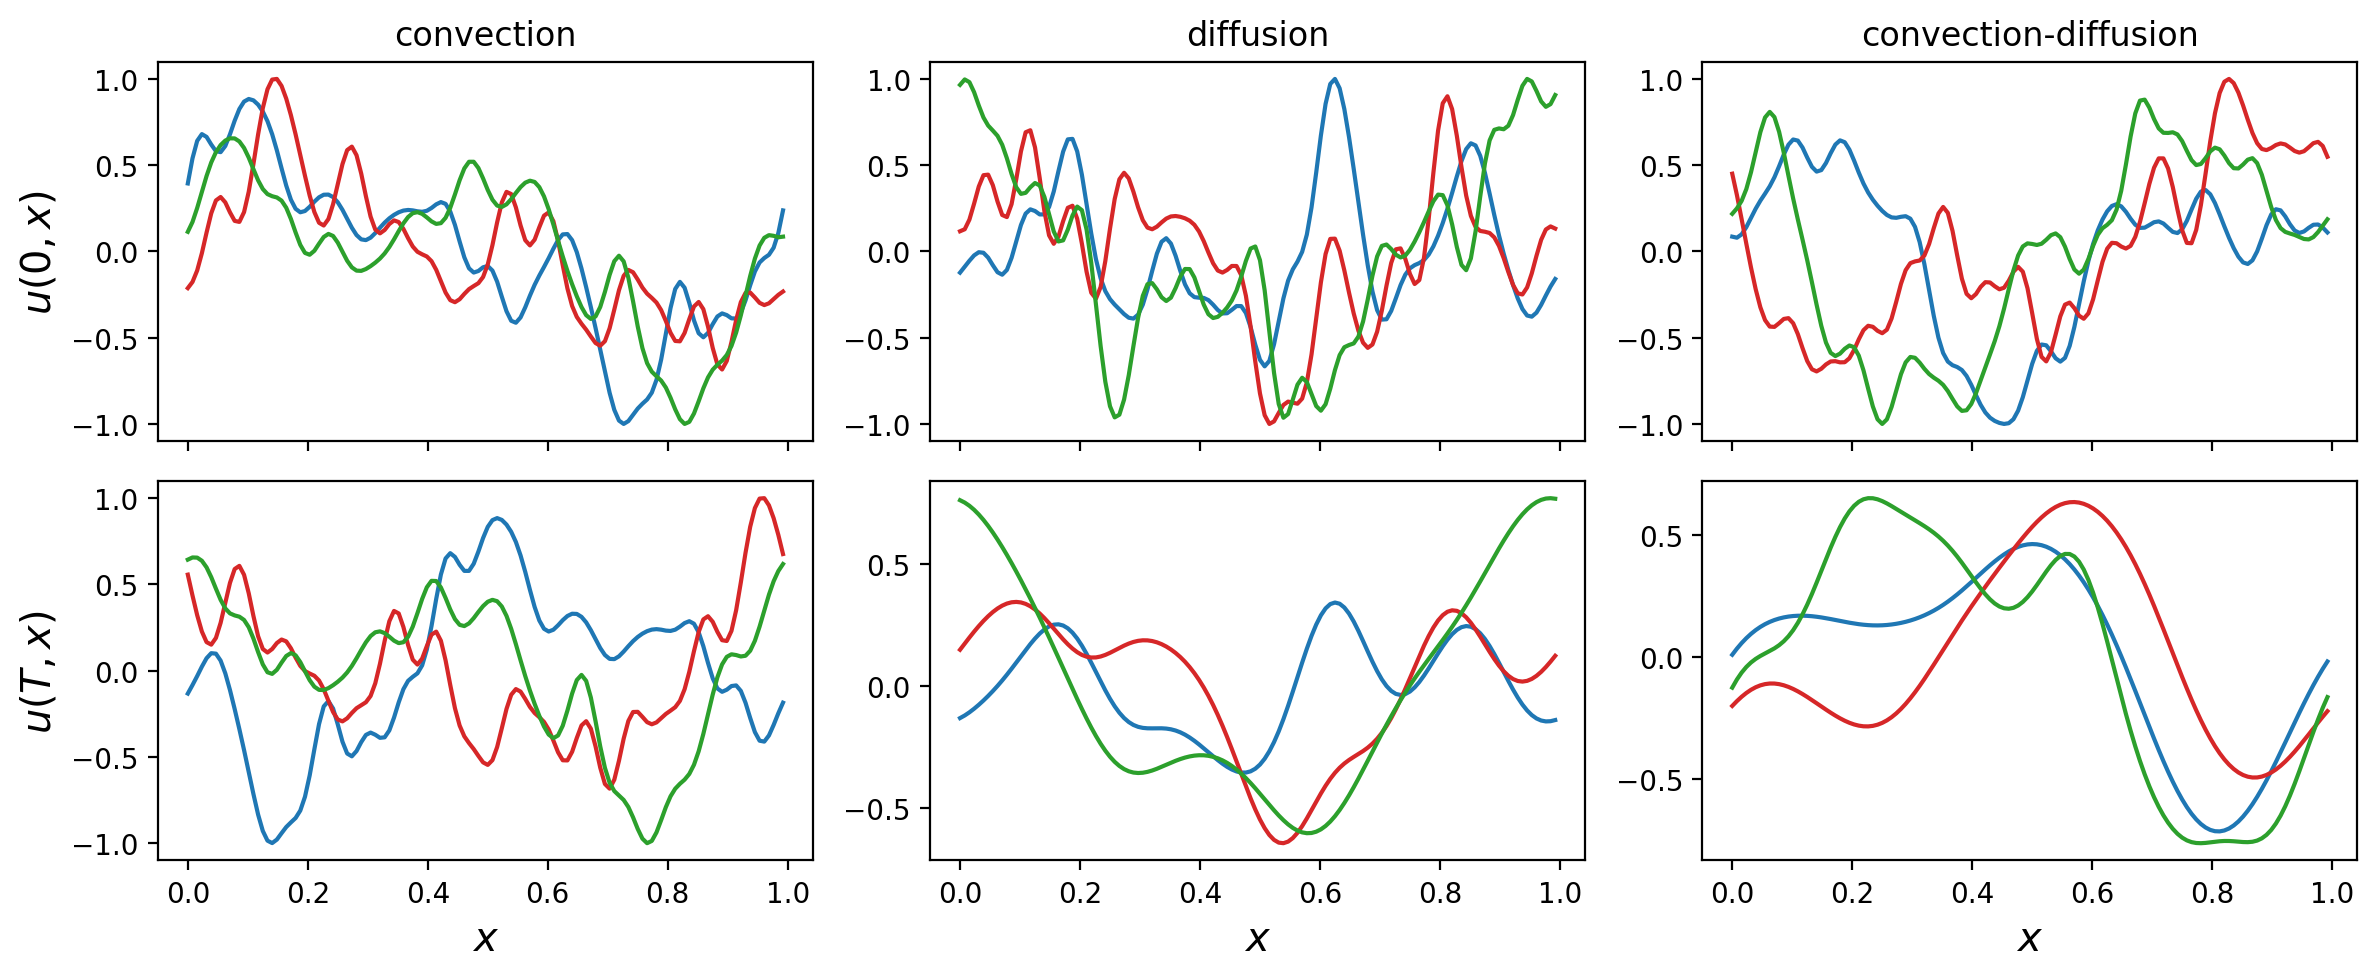

In [6]:
def plot_datasets(figure_name=None):
    titles = {"convection": "convection", "diffusion": "diffusion", "both": "convection-diffusion"}
    fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True)
    for j, (kind, (f, u)) in enumerate(datasets.items()):
        for i, color in zip(range(3), ["tab:blue", "tab:red", "tab:green"]):
            axes[0, j].plot(x, f[i, 0], color=color)
            axes[1, j].plot(x, u[i, 0], color=color)
        axes[0, j].set_title(titles[kind])
        axes[1, j].set_xlabel("$x$", fontsize="x-large")
    axes[0, 0].set_ylabel("$u(0, x)$", fontsize="x-large")
    axes[1, 0].set_ylabel("$u(T, x)$", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_dataset.pdf", format='pdf', bbox_inches='tight')

plot_datasets(figure_name="ConvectionDiffusion")

# Training protocol

- **Splits.** For every dataset the first 900 samples are for training and the last 100 for testing, except for the convection-diffusion dataset: its first 200 samples are the test set, the next 100 are a validation set (used only to choose the learning rate and the number of steps), and the remaining 4700 samples (the dataset has 5000 samples) are the pool from which the training samples for the finetuning and for the training from scratch are drawn.
- **Optimisation.** The Lion optimiser with a cosine decay of the learning rate. The number of updates is fixed (and not the number of epochs), so that the runs with different numbers of samples get the same budget. The learning rate and the number of steps are chosen on the validation set, separately for the training from scratch and for the finetuning and separately for every number of training samples $N$ (a larger $N$ may need a longer training), so that neither of the two is handicapped.
- **Metric.** The relative error $\|u_\theta-u\|_2/\|u\|_2$ averaged over the 200 test samples of the convection-diffusion dataset.

In [7]:
N_processor, N_layers, N_modes = 32, 3, 16
N_batch = 20

def new_model(seed):
    # the inputs: the coordinate, u(0, x), c, nu
    return FFNO(N_layers, [4, N_processor, 1], N_modes, 1, random.PRNGKey(seed), s1=1e-1, s2=0, s3=1e-1)

def fit(model, features, targets, N_steps, learning_rate, seed):
    schedule = optax.cosine_decay_schedule(learning_rate, N_steps, alpha=1e-2)
    optim = optax.lion(learning_rate=schedule)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))
    n = random.choice(random.PRNGKey(seed), features.shape[0], shape=(N_steps, min(N_batch, features.shape[0])))
    make_step_scan_ = lambda carry, n: l2_make_step_scan(carry, n, optim)
    carry, history = scan(make_step_scan_, [model, features, targets, coordinates, opt_state], n)
    return carry[0], history

def predict(model, features):
    # sample by sample, as in the previous notebooks (a single vmap over hundreds of samples gave wrong results on our GPU)
    return scan(make_prediction_scan, [model, features, coordinates], jnp.arange(features.shape[0]))[1]

def relative_errors(predictions, targets):
    return (jnp.linalg.norm(predictions - targets, axis=2) / jnp.linalg.norm(targets, axis=2))[:, 0]

def evaluate(model, features, targets):
    return relative_errors(predict(model, features), targets)

features_both, targets_both = datasets["both"]
test = (features_both[:200], targets_both[:200])
validation = (features_both[200:300], targets_both[200:300])
pool = (features_both[300:], targets_both[300:])

def sample_pool(N, seed):
    # N random samples of the pool
    ind = np.random.default_rng(seed).permutation(pool[0].shape[0])[:N]
    return pool[0][ind], pool[1][ind]

# Pretraining

The network is trained on the union of the training parts of the convection and the diffusion datasets (1800 samples). Note that the network never sees both constants non-zero. We report the errors on the test parts of these two datasets.

In [8]:
features_pretrain = jnp.concatenate([datasets["convection"][0][:900], datasets["diffusion"][0][:900]])
targets_pretrain = jnp.concatenate([datasets["convection"][1][:900], datasets["diffusion"][1][:900]])

start = time.time()
pretrained, history = fit(new_model(0), features_pretrain, targets_pretrain, 10000, 1e-3, 0)
history.block_until_ready()
print(f"Pretraining time: {time.time() - start:.1f} s")
print("Number of parameters:", sum(2*a.size if jnp.iscomplexobj(a) else a.size for a in tree_leaves(eqx.filter(pretrained, eqx.is_array))))
for kind in ["convection", "diffusion"]:
    e = evaluate(pretrained, *[a[900:] for a in datasets[kind]])
    print(f"Test error, {kind}: mean {jnp.mean(e):.4f}, median {jnp.median(e):.4f}")

Pretraining time: 9.8 s
Number of parameters: 104833


Test error, convection: mean 0.0637, median 0.0570
Test error, diffusion: mean 0.0046, median 0.0042


# Zero-shot

The pretrained network is applied to the test part of the convection-diffusion dataset with no additional training.

- **Direct**: the input is $(u_0, c, \nu)$ with both constants non-zero. This combination never appeared in the pretraining.
- **Composed**: the exact solution is the composition of the two pure solution operators, so we call the same network twice: first with the input $(u_0, c, 0)$ and then, with its output as the initial condition, with $(\cdot, 0, \nu)$.

**Note.** The composed call is *not* a fair zero-shot baseline. It uses explicit prior knowledge that we, and not the network, supply: that the solution operator of the combined problem is the composition of the two pure operators (which is true for this linear problem with constant coefficients, but is not true in general, e.g., for the Burgers equation), and in which order and with which inputs to apply them. The network has not learned this structure. We keep this baseline as a reference for what is possible when the structure is known, and the **direct call is the actual zero-shot test** of the network.

In [9]:
def predict_composed(model, features):
    first = features.at[:, 2].set(0.0)  # convection only
    u1 = predict(model, first)
    second = jnp.concatenate([u1, jnp.zeros_like(features[:, 1:2]), features[:, 2:3]], axis=1)  # diffusion only
    return predict(model, second)

errors_direct = evaluate(pretrained, *test)
predictions_composed = predict_composed(pretrained, test[0])
errors_composed = relative_errors(predictions_composed, test[1])
for name, e in [("direct", errors_direct), ("composed", errors_composed)]:
    print(f"Zero-shot, {name:<9} mean {jnp.mean(e):.4f}  median {jnp.median(e):.4f}  min {jnp.min(e):.4f}  max {jnp.max(e):.4f}")

Zero-shot, direct    mean 2.1776  median 1.9812  min 0.4988  max 6.1057
Zero-shot, composed  mean 0.0112  median 0.0091  min 0.0032  max 0.0567


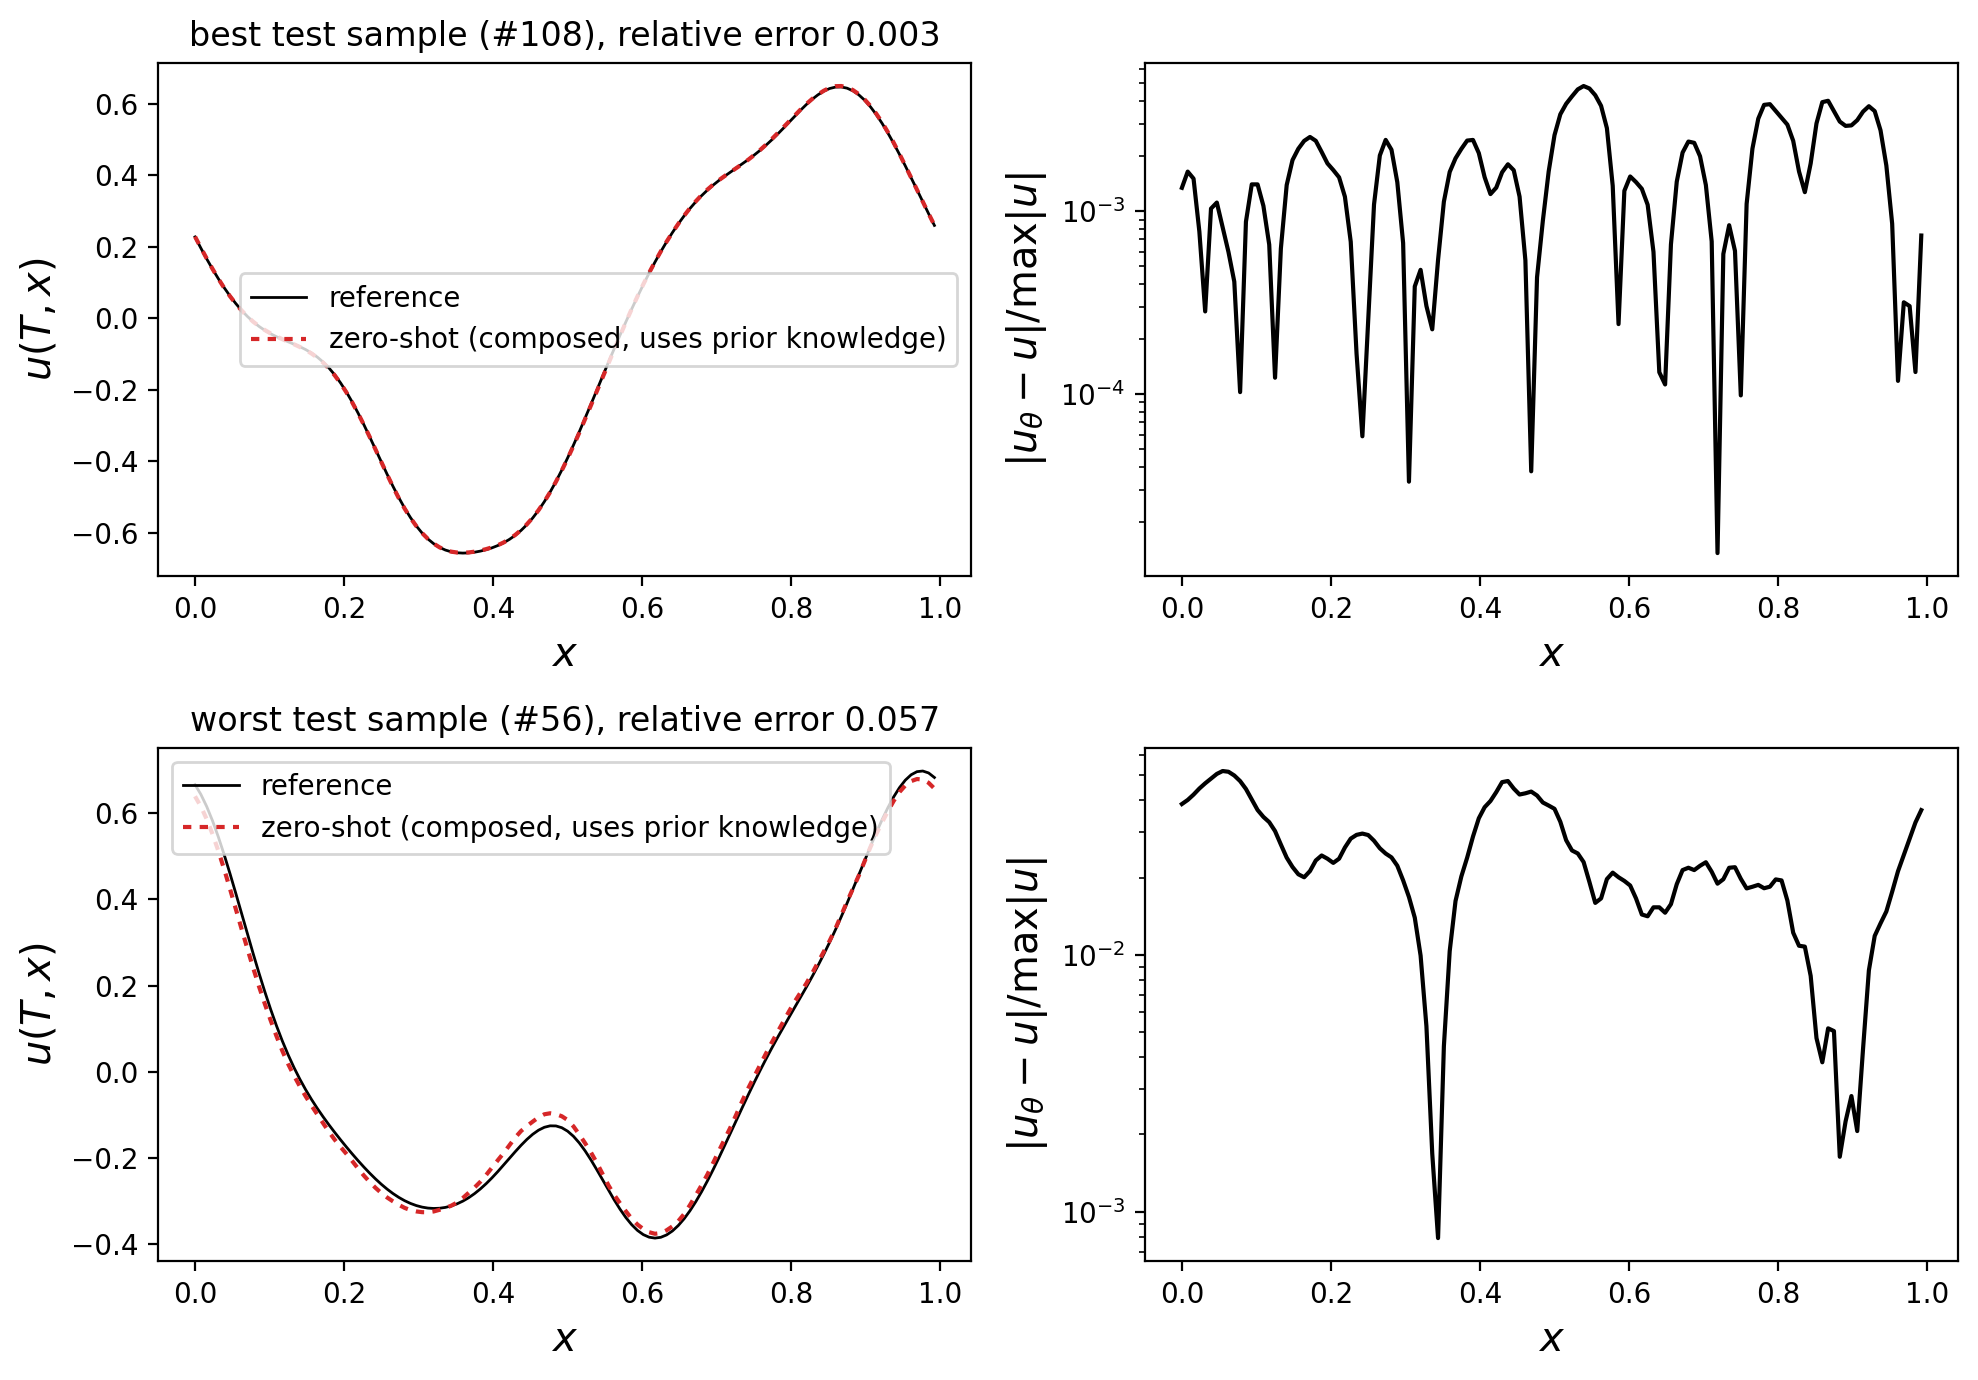

In [10]:
def plot_samples(errors, predictions, targets, label, figure_name=None):
    # the best and the worst samples
    selected = {"best": jnp.argmin(errors), "worst": jnp.argmax(errors)}
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for row, (name, i) in zip(axes, selected.items()):
        u, u_pred = targets[i, 0], predictions[i, 0]
        row[0].plot(x, u, color="black", label="reference", linewidth=1.0)
        row[0].plot(x, u_pred, color="tab:red", dashes=[2, 2, 2, 2], label=label, linewidth=1.5)
        row[0].set_ylabel("$u(T, x)$", fontsize="x-large")
        row[0].set_title(f"{name} test sample (#{int(i)}), relative error {errors[i]:.3f}")
        row[0].legend()
        row[1].plot(x, jnp.abs(u_pred - u) / jnp.max(jnp.abs(u)), color="black")
        row[1].set_yscale("log")
        row[1].set_ylabel("$|u_\\theta - u| / \\max|u|$", fontsize="x-large")
        for ax in row:
            ax.set_xlabel("$x$", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_solutions.pdf", format='pdf', bbox_inches='tight')

plot_samples(errors_composed, predictions_composed, test[1], "zero-shot (composed, uses prior knowledge)", figure_name="FoundationModel_zero_shot")

# Finetuning and data efficiency

For every $N\in\{5, 10, 20, 50, 100, 300, 1000, 3000\}$ we first choose the learning rate and the number of steps on the validation set (one seed, a grid of 3 numbers of steps $\times$ 2 or 3 learning rates for each of the two methods). Then, for the chosen values and for 5 random seeds (they change the samples drawn from the pool, the initialisation of the scratch network and the order of the minibatches) we train

- a network **from scratch**, and
- the **pretrained** network (finetuning, all weights are updated)

and evaluate them on the test set. The pretrained network is the same in all runs.

In [11]:
N_list = [5, 10, 20, 50, 100, 300, 1000, 3000]
seeds = range(5)
lr_grid = {"scratch": [3e-4, 1e-3], "finetuned": [3e-5, 1e-4, 3e-4]}
step_grid = [3000, 10000, 30000]

def select_hyperparameters(N):
    # the number of steps and the learning rate with the smallest validation error
    f_select, t_select = sample_pool(N, 0)
    chosen = {}
    for name in ["scratch", "finetuned"]:
        best_error = np.inf
        for N_steps in step_grid:
            for lr in lr_grid[name]:
                model = new_model(0) if name == "scratch" else pretrained
                model, _ = fit(model, f_select, t_select, N_steps, lr, 0)
                error = float(jnp.mean(evaluate(model, *validation)))
                if error < best_error:
                    best_error, chosen[name] = error, (N_steps, lr)
    return chosen

start = time.time()
chosen = {}
print("   N    scratch: steps, lr     finetuned: steps, lr")
for N in N_list:
    chosen[N] = select_hyperparameters(N)
    print(f"{N:4d}    {chosen[N]['scratch'][0]:6d}, {chosen[N]['scratch'][1]:.0e}        {chosen[N]['finetuned'][0]:6d}, {chosen[N]['finetuned'][1]:.0e}", flush=True)
print(f"Selection time: {time.time() - start:.0f} s")

   N    scratch: steps, lr     finetuned: steps, lr


   5     10000, 1e-03         30000, 3e-05


  10     30000, 3e-04         10000, 1e-04


  20      3000, 3e-04          3000, 1e-04


  50     10000, 3e-04         30000, 3e-05


 100     10000, 3e-04         30000, 3e-05


 300     30000, 3e-04         30000, 1e-04


1000     30000, 1e-03         30000, 1e-04


3000     30000, 1e-03         30000, 1e-04


Selection time: 1006 s


In [12]:
results = {name: np.zeros((len(N_list), len(seeds))) for name in ["scratch", "finetuned"]}

start = time.time()
for i, N in enumerate(N_list):
    for j, seed in enumerate(seeds):
        f_train, t_train = sample_pool(N, seed)
        for name in results:
            N_steps, lr = chosen[N][name]
            model = new_model(seed + 1) if name == "scratch" else pretrained
            model, _ = fit(model, f_train, t_train, N_steps, lr, seed)
            results[name][i, j] = float(jnp.mean(evaluate(model, *test)))
    print(f"N = {N:4d}: scratch {results['scratch'][i].mean():.4f}, finetuned {results['finetuned'][i].mean():.4f}", flush=True)
print(f"Total time: {time.time() - start:.0f} s")

N =    5: scratch 1.0601, finetuned 0.7319


N =   10: scratch 1.0300, finetuned 0.4153


N =   20: scratch 0.7662, finetuned 0.1903


N =   50: scratch 0.3156, finetuned 0.0600


N =  100: scratch 0.1588, finetuned 0.0198


N =  300: scratch 0.0298, finetuned 0.0091


N = 1000: scratch 0.0120, finetuned 0.0061


N = 3000: scratch 0.0063, finetuned 0.0054


Total time: 955 s


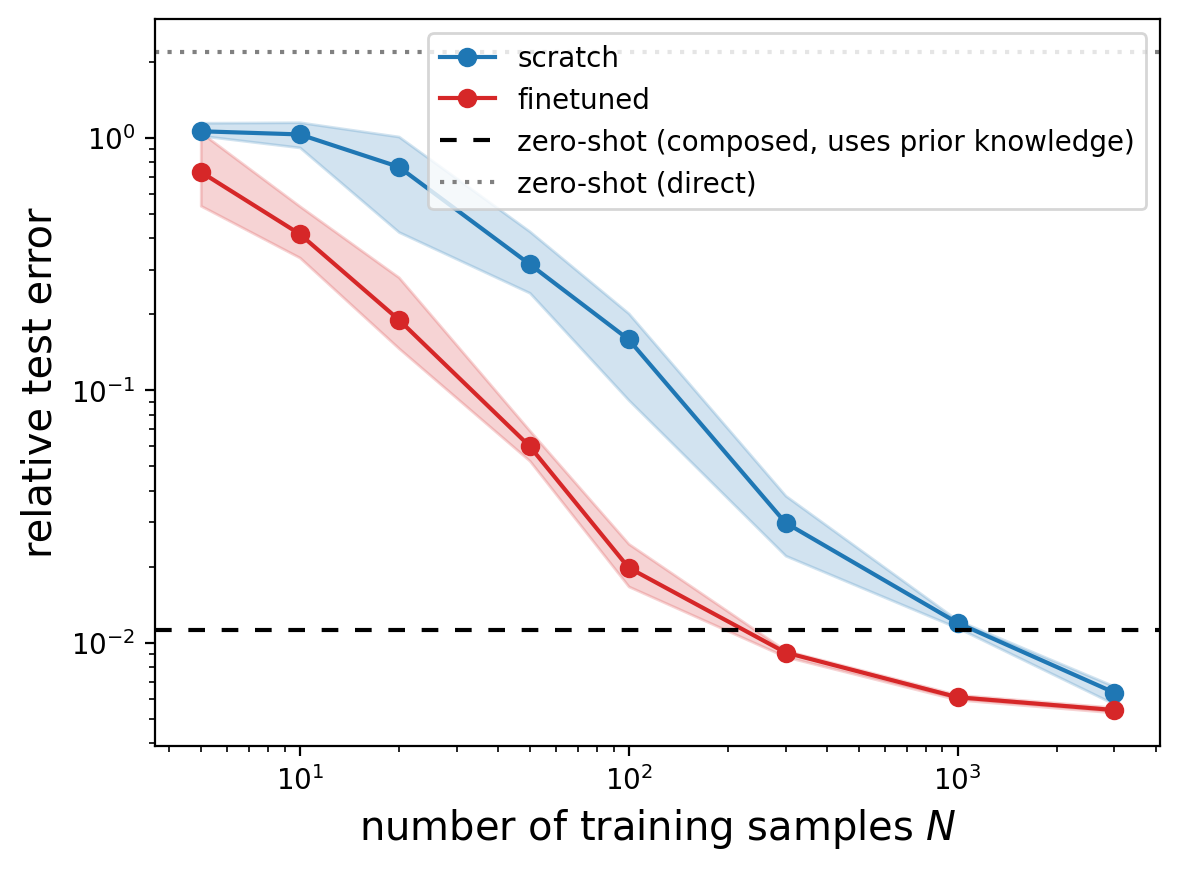

In [13]:
def plot_data_efficiency(figure_name=None):
    fig, ax = plt.subplots(1, 1, figsize=(6, 4.5))
    for name, color in [("scratch", "tab:blue"), ("finetuned", "tab:red")]:
        r = results[name]
        ax.plot(N_list, r.mean(axis=1), color=color, marker="o", label=name)
        ax.fill_between(N_list, r.min(axis=1), r.max(axis=1), color=color, alpha=0.2)
    ax.axhline(jnp.mean(errors_composed), color="black", dashes=[4, 4], label="zero-shot (composed, uses prior knowledge)")
    ax.axhline(jnp.mean(errors_direct), color="gray", dashes=[1, 2], label="zero-shot (direct)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("number of training samples $N$", fontsize="x-large")
    ax.set_ylabel("relative test error", fontsize="x-large")
    ax.legend()
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_data_efficiency.pdf", format='pdf', bbox_inches='tight')

plot_data_efficiency(figure_name="FoundationModel")

In [14]:
print("   N    scratch (mean +- std)    finetuned (mean +- std)")
for i, N in enumerate(N_list):
    s, f = results["scratch"][i], results["finetuned"][i]
    print(f"{N:4d}    {s.mean():.4f} +- {s.std():.4f}       {f.mean():.4f} +- {f.std():.4f}")

   N    scratch (mean +- std)    finetuned (mean +- std)
   5    1.0601 +- 0.0443       0.7319 +- 0.1793
  10    1.0300 +- 0.0766       0.4153 +- 0.0776
  20    0.7662 +- 0.2118       0.1903 +- 0.0466
  50    0.3156 +- 0.0604       0.0600 +- 0.0067
 100    0.1588 +- 0.0374       0.0198 +- 0.0028
 300    0.0298 +- 0.0055       0.0091 +- 0.0002
1000    0.0120 +- 0.0003       0.0061 +- 0.0001
3000    0.0063 +- 0.0004       0.0054 +- 0.0001


# Summary

Relative test errors on the convection-diffusion dataset (mean over the 200 test samples; for the training runs also mean $\pm$ standard deviation over 5 seeds). The network is a small FNO with about $10^5$ parameters; the pretraining on the convection and diffusion datasets takes 10 s.

| Method | Test error |
|---|---|
| zero-shot, direct call | 2.178 |
| zero-shot, composed call (uses prior knowledge, see the note above) | 0.0112 |

| $N$ | from scratch | finetuned |
|---|---|---|
| 5 | 1.060 $\pm$ 0.044 | 0.732 $\pm$ 0.179 |
| 10 | 1.030 $\pm$ 0.077 | 0.415 $\pm$ 0.078 |
| 20 | 0.766 $\pm$ 0.212 | 0.190 $\pm$ 0.047 |
| 50 | 0.316 $\pm$ 0.060 | 0.060 $\pm$ 0.007 |
| 100 | 0.159 $\pm$ 0.037 | 0.0198 $\pm$ 0.0028 |
| 300 | 0.0298 $\pm$ 0.0055 | 0.0091 $\pm$ 0.0002 |
| 1000 | 0.0120 $\pm$ 0.0003 | 0.0061 $\pm$ 0.0001 |
| 3000 | 0.0063 $\pm$ 0.0004 | 0.0054 $\pm$ 0.0001 |

**Conclusion.**

- The pretrained network does not solve the new problem by itself: the direct zero-shot error is above 1 (the output is not better than zero), because the network has never seen both constants non-zero. The composed call works well (1.1%), but it relies on prior knowledge about the structure of the problem, which we supplied, and it would fail for a nonlinear equation. It is a reference, and not an evidence of the "knowledge" of the network.
- Finetuning is better than the training from scratch for all $N$. The gain is large for small data: for $N=50$-$100$ the error is 5-8 times smaller, and the finetuned network with $N=100$ is better than the network from scratch with $N=300$. In terms of data, the pretraining saves a factor of about 3-4 in the number of samples between $N=100$ and $N=3000$. With $N\lesssim10$ neither of the methods is useful.
- The gain shrinks when data is abundant: for $N=3000$ the two errors are 0.0054 and 0.0063. The finetuned network flattens at about $5\cdot10^{-3}$, which is probably a limit of the small network and of the training, and not of the data.
- Caveat: for $N\geq300$ the chosen number of steps (30000) and, for the scratch training, also the learning rate ($10^{-3}$ for $N\geq1000$) are on the border of our search grid, so both methods, and the scratch training in particular, may improve a little with a longer training; the differences at large $N$ should not be over-interpreted.
- The toy problem is linear with constant coefficients, and the pretraining tasks are exactly its two factors, so this is the most favourable case for the transfer. How much of it carries over to real foundation models is an open question.